# Sales & Customer Analytics Dashboard

## 1. Project Overview
This project focuses on analyzing retail sales and customer data to understand business performance, identify sales trends, and gain insights into customer purchasing behavior.

## 2. Business Problem
Retail businesses generate large amounts of sales data, but understanding which products perform well, which customers contribute the most revenue, and which regions generate higher sales can be challenging.

This project uses data analytics to turn raw sales data into meaningful business insights.

## 3. Project Objectives
- Analyze overall sales and profitability.
- Identify top-performing products and categories.
- Understand customer purchasing behavior.
- Evaluate regional sales performance.
- Identify monthly and yearly sales trends.
- Develop an interactive dashboard for business insights.

## 4. Tools and Technologies
- **Python:** Data analysis and preprocessing.
- **Pandas and NumPy:** Data manipulation.
- **Matplotlib and Seaborn:** Data visualization.
- **SQL:** Business data analysis.
- **Power BI:** Interactive dashboard development.

## 5. Expected Outcome
A complete analytics solution that transforms raw retail data into meaningful insights through Python analysis, SQL queries, and an interactive Power BI dashboard.

In [ ]:
# Step 1: Create the Project Directory and Folder Structure

from pathlib import Path

# Define the main project directory
PROJECT_DIR = Path("/content/Sales_Customer_Analytics")

# Define the required project folders
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "sql",
    "reports/charts",
    "powerbi",
    "docs"
]

# Create all project folders
for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Create the .gitignore file
gitignore_content = """
__pycache__/
*.pyc
.ipynb_checkpoints/
.env
.DS_Store
"""

(PROJECT_DIR / ".gitignore").write_text(
    gitignore_content.strip() + "\n"
)

# Create the requirements.txt file
requirements_content = """
pandas
numpy
matplotlib
seaborn
sqlalchemy
openpyxl
"""

(PROJECT_DIR / "requirements.txt").write_text(
    requirements_content.strip() + "\n"
)

print("Project structure created successfully!")
print("\nProject folders:")

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_dir():
        print(f"📁 {path.relative_to(PROJECT_DIR)}/")
    else:
        print(f"📄 {path.relative_to(PROJECT_DIR)}")

Project structure created successfully!

Project folders:
📄 .gitignore
📁 data/
📁 data/processed/
📁 data/raw/
📁 docs/
📁 notebooks/
📁 powerbi/
📁 reports/
📁 reports/charts/
📄 requirements.txt
📁 sql/


In [ ]:
# Step 2: Download and Load the Retail Sales Dataset

import pandas as pd

# Define the dataset source
DATA_URL = (
    "https://raw.githubusercontent.com/curran/data/"
    "gh-pages/superstoreSales/superstoreSales.csv"
)

# Download and load the dataset using Latin-1 encoding
df = pd.read_csv(DATA_URL, encoding="latin-1")

# Save the original dataset
raw_file = PROJECT_DIR / "data" / "raw" / "superstore_sales.csv"
df.to_csv(raw_file, index=False)

# Display dataset overview
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five records
print("\nFirst five records:")
display(df.head())

# Display dataset information
print("\nDataset information:")
df.info()

Dataset downloaded successfully!
Dataset shape: (8399, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Order Priority', 'Order Quantity', 'Sales', 'Discount', 'Ship Mode', 'Profit', 'Unit Price', 'Shipping Cost', 'Customer Name', 'Province', 'Region', 'Customer Segment', 'Product Category', 'Product Sub-Category', 'Product Name', 'Product Container', 'Product Base Margin', 'Ship Date']

First five records:


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.5400,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,10123.0200,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.5700,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483,7/10/2011,High,30,4965.7595,0.08,Regular Air,1198.97,195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515,8/28/2010,Not Specified,19,394.2700,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   object 
 3   Order Priority        8399 non-null   object 
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   object 
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   object 
 12  Province              8399 non-null   object 
 13  Region                8399 non-null   object 
 14  Customer Segment      8399 non-null   object 
 15 

In [ ]:
# Step 3: Inspect Data Quality and Identify Data Issues

# Check the dataset dimensions
print("Dataset Shape:", df.shape)

# Check missing values in each column
print("\nMissing Values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# Check duplicate records
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# Check data types
print("\nColumn Data Types:")
print(df.dtypes)

# Generate statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Check unique values in important business columns
print("\nUnique Customer Names:", df["Customer Name"].nunique())
print("Unique Order IDs:", df["Order ID"].nunique())
print("Unique Products:", df["Product Name"].nunique())
print("Product Categories:", df["Product Category"].unique())

Dataset Shape: (8399, 21)

Missing Values:
Product Base Margin    63
dtype: int64

Number of Duplicate Rows:
0

Column Data Types:
Row ID                    int64
Order ID                  int64
Order Date               object
Order Priority           object
Order Quantity            int64
Sales                   float64
Discount                float64
Ship Mode                object
Profit                  float64
Unit Price              float64
Shipping Cost           float64
Customer Name            object
Province                 object
Region                   object
Customer Segment         object
Product Category         object
Product Sub-Category     object
Product Name             object
Product Container        object
Product Base Margin     float64
Ship Date                object
dtype: object

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,8399.0,NaN,NaN,NaN,4200.0,2424.726789,1.0,2100.5,4200.0,6299.5,8399.0
Order ID,8399.0,NaN,NaN,NaN,29965.179783,17260.883447,3.0,15011.5,29857.0,44596.0,59973.0
Order Date,8399,1418,9/15/2011,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Priority,8399,5,High,1768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Quantity,8399.0,NaN,NaN,NaN,25.571735,14.481071,1.0,13.0,26.0,38.0,50.0
Sales,8399.0,NaN,NaN,NaN,1775.878179,3585.050525,2.24,143.195,449.42,1709.32,89061.05
Discount,8399.0,NaN,NaN,NaN,0.049671,0.031823,0.0,0.02,0.05,0.08,0.25
Ship Mode,8399,3,Regular Air,6270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,8399.0,NaN,NaN,NaN,181.184424,1196.653371,-14140.7,-83.315,-1.5,162.75,27220.69
Unit Price,8399.0,NaN,NaN,NaN,89.346259,290.354383,0.99,6.48,20.99,85.99,6783.02



Unique Customer Names: 795
Unique Order IDs: 5496
Unique Products: 1263
Product Categories: ['Office Supplies' 'Technology' 'Furniture']


In [ ]:
# Step 4: Clean and Preprocess the Retail Sales Dataset

# Create a copy to preserve the original dataset
df_clean = df.copy()

# Convert date columns into datetime format
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Check missing values before handling them
print("Missing values before cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Fill missing Product Base Margin values using the median
margin_median = df_clean["Product Base Margin"].median()

df_clean["Product Base Margin"] = (
    df_clean["Product Base Margin"].fillna(margin_median)
)

# Verify date conversion
print("\nDate column data types:")
print(df_clean[["Order Date", "Ship Date"]].dtypes)

# Verify missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Save the cleaned dataset
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

cleaned_file = PROCESSED_DATA_DIR / "cleaned_sales_data.csv"
df_clean.to_csv(cleaned_file, index=False)

print("\nData cleaning completed successfully!")
print("Cleaned dataset shape:", df_clean.shape)
print("Cleaned dataset saved to:", cleaned_file)

Missing values before cleaning:
Product Base Margin    63
dtype: int64

Date column data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

Missing values after cleaning:
Series([], dtype: int64)

Data cleaning completed successfully!
Cleaned dataset shape: (8399, 21)
Cleaned dataset saved to: /content/Sales_Customer_Analytics/data/processed/cleaned_sales_data.csv


In [ ]:
# Step 5: Create Business Features for Sales and Customer Analysis

# Extract year and month from Order Date
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Order Month Name"] = df_clean["Order Date"].dt.strftime("%B")
df_clean["Order Year-Month"] = df_clean["Order Date"].dt.to_period("M").astype(str)

# Calculate shipping duration in days
df_clean["Shipping Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

# Calculate profit margin as a percentage of sales
df_clean["Profit Margin"] = (
    df_clean["Profit"] / df_clean["Sales"]
) * 100

# Calculate average order value for each order
order_sales = df_clean.groupby("Order ID")["Sales"].transform("sum")

df_clean["Order Value"] = order_sales

# Display the newly created columns
new_columns = [
    "Order Year",
    "Order Month",
    "Order Month Name",
    "Order Year-Month",
    "Shipping Days",
    "Profit Margin",
    "Order Value"
]

display(df_clean[new_columns].head())

# Save the updated dataset
df_clean.to_csv(cleaned_file, index=False)

print("Feature engineering completed successfully!")
print("Updated dataset shape:", df_clean.shape)

,Order Year,Order Month,Order Month Name,Order Year-Month,Shipping Days,Profit Margin,Order Value
0,2010,10,October,2010-10,7,-81.536285,261.5400
1,2012,10,October,2012-10,1,4.522465,10367.5900
2,2012,10,October,2012-10,2,19.098827,10367.5900
3,2011,7,July,2011-07,2,24.144746,4965.7595
4,2010,8,August,2010-08,2,7.847414,540.9600


Feature engineering completed successfully!
Updated dataset shape: (8399, 28)


In [ ]:
# Step 6: Calculate Key Business Performance Indicators (KPIs)

# Calculate overall sales and profit
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()

# Calculate order and customer metrics
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer Name"].nunique()

# Calculate average order value using one total per order
order_totals = df_clean.groupby("Order ID")["Sales"].sum()
average_order_value = order_totals.mean()

# Calculate overall profit margin
overall_profit_margin = (total_profit / total_sales) * 100

# Display key business metrics
print("=" * 45)
print("       SALES & CUSTOMER ANALYTICS")
print("=" * 45)

print(f"Total Sales:             ${total_sales:,.2f}")
print(f"Total Profit:            ${total_profit:,.2f}")
print(f"Total Orders:            {total_orders:,}")
print(f"Unique Customers:        {total_customers:,}")
print(f"Average Order Value:     ${average_order_value:,.2f}")
print(f"Overall Profit Margin:   {overall_profit_margin:.2f}%")

print("=" * 45)

       SALES & CUSTOMER ANALYTICS
Total Sales:             $14,915,600.82
Total Profit:            $1,521,767.98
Total Orders:            5,496
Unique Customers:        795
Average Order Value:     $2,713.90
Overall Profit Margin:   10.20%


In [ ]:
# Step 7: Analyze Sales and Profit by Product Category

# Calculate sales and profit by category
category_analysis = (
    df_clean.groupby("Product Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Order Quantity", "sum")
    )
    .reset_index()
)

# Calculate profit margin by category
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

# Sort categories by sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display category performance
display(category_analysis.round(2))

# Analyze sales and profit by sub-category
subcategory_analysis = (
    df_clean.groupby("Product Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

print("\nTop 10 Product Sub-Categories by Sales:")
display(subcategory_analysis.head(10).round(2))

,Product Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
2,Technology,5984248.18,886313.52,52175,14.81
0,Furniture,5178590.54,117433.03,44324,2.27
1,Office Supplies,3752762.10,518021.43,118278,13.80



Top 10 Product Sub-Categories by Sales:


,Product Sub-Category,Total_Sales,Total_Profit
9,Office Machines,2168697.14,307712.93
15,Tables,1896008.14,-99062.50
16,Telephones and Communication,1889313.80,316951.62
3,Chairs & Chairmats,1761836.55,149649.73
5,Copiers and Fax,1130361.30,167361.49
14,Storage & Organization,1070182.60,6664.15
1,Binders and Binder Accessories,1022957.59,307413.39
2,Bookcases,822652.04,-33582.13
4,Computer Peripherals,795875.94,94287.48
0,Appliances,736991.54,97158.06


In [ ]:
# Step 8: Analyze Sales and Profit Across Regions

# Calculate sales and profit by region
region_analysis = (
    df_clean.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Order Quantity", "sum")
    )
    .reset_index()
)

# Calculate regional profit margin
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"]
) * 100

# Calculate sales contribution percentage
region_analysis["Sales_Contribution"] = (
    region_analysis["Total_Sales"] /
    total_sales
) * 100

# Sort regions by sales
region_analysis = region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display regional performance
print("Regional Sales and Profit Analysis:")
display(region_analysis.round(2))

# Analyze sales by province
province_analysis = (
    df_clean.groupby("Province")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

print("\nTop 10 Provinces by Sales:")
display(province_analysis.head(10).round(2))

Regional Sales and Profit Analysis:


,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin,Sales_Contribution
6,West,3597549.28,297008.61,1330,51423,8.26,24.12
3,Ontario,3063212.48,346868.54,1235,46685,11.32,20.54
4,Prarie,2837304.60,321160.12,1148,43732,11.32,19.02
0,Atlantic,2014248.20,238960.66,748,28068,11.86,13.50
5,Quebec,1510195.08,140426.65,587,19589,9.30,10.12
7,Yukon,975867.37,73849.21,396,13596,7.57,6.54
1,Northwest Territories,800847.33,100653.08,269,9722,12.57,5.37
2,Nunavut,116376.48,2841.11,56,1962,2.44,0.78



Top 10 Provinces by Sales:


,Province,Total_Sales,Total_Profit
8,Ontario,3063212.48,346868.54
1,British Columbia,1892757.78,145062.13
0,Alberta,1704791.49,151946.48
10,Quebec,1510195.08,140426.65
11,Saskachewan,1464455.82,184732.96
2,Manitoba,1372848.78,136427.16
12,Yukon,975867.37,73849.21
6,Nova Scotia,817729.36,85361.87
5,Northwest Territories,800847.33,100653.08
3,New Brunswick,684211.52,115351.94


In [ ]:
# Step 9: Analyze Sales and Profit by Customer Segment

# Calculate performance for each customer segment
segment_analysis = (
    df_clean.groupby("Customer Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer Name", "nunique"),
        Total_Quantity=("Order Quantity", "sum")
    )
    .reset_index()
)

# Calculate profit margin for each segment
segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"]
) * 100

# Sort segments by sales
segment_analysis = segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Display customer segment performance
print("Customer Segment Performance:")
display(segment_analysis.round(2))

# Identify the top 10 customers by total sales
customer_analysis = (
    df_clean.groupby("Customer Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
    .sort_values(by="Total_Sales", ascending=False)
)

print("\nTop 10 Customers by Sales:")
display(customer_analysis.head(10).round(2))

Customer Segment Performance:


,Customer Segment,Total_Sales,Total_Profit,Total_Orders,Unique_Customers,Total_Quantity,Profit_Margin
1,Corporate,5498904.88,599746.00,2002,353,78517,10.91
2,Home Office,3564763.88,318354.03,1341,246,52807,8.93
0,Consumer,3063611.08,287959.94,1076,197,41760,9.40
3,Small Business,2788320.99,315708.01,1077,193,41693,11.32



Top 10 Customers by Sales:


,Customer Name,Total_Sales,Total_Profit,Total_Orders
261,Emily Phan,117124.44,34005.44,8
218,Deborah Brumfield,97433.14,31121.22,12
659,Roy Skaria,92542.15,1343.94,18
732,Sylvia Foulston,88875.76,5141.90,18
309,Grant Carroll,88417.00,27977.29,17
17,Alejandro Grove,83561.93,20588.92,9
198,Darren Budd,81577.34,1857.66,26
405,Julia Barnett,80044.45,-1956.09,12
392,John Lucas,79696.19,12725.08,14
472,Liz MacKendrick,76306.43,20397.24,14


Monthly Sales Performance:


,Order Year-Month,Total_Sales,Total_Profit
0,2009-01,516302.96,62326.40
1,2009-02,332480.64,30422.68
2,2009-03,411628.73,22802.96
3,2009-04,393276.48,39132.73
4,2009-05,230145.54,18035.35
5,2009-06,263456.07,34640.55
6,2009-07,380503.97,41749.43
7,2009-08,329754.72,14682.84
8,2009-09,325292.31,46652.05
9,2009-10,361555.27,55228.01



Yearly Sales Performance:


,Order Year,Total_Sales,Total_Profit
0,2009,4209139.46,434538.73
1,2010,3549680.80,363871.48
2,2011,3436816.70,381455.99
3,2012,3719963.86,341901.78


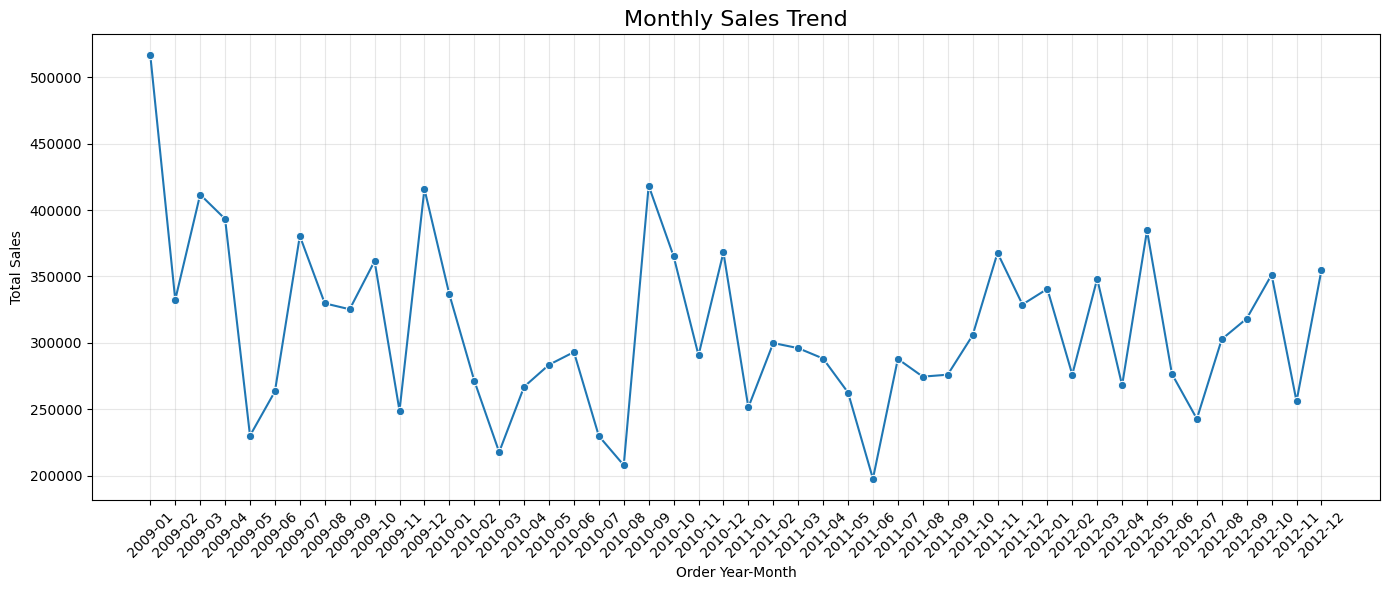

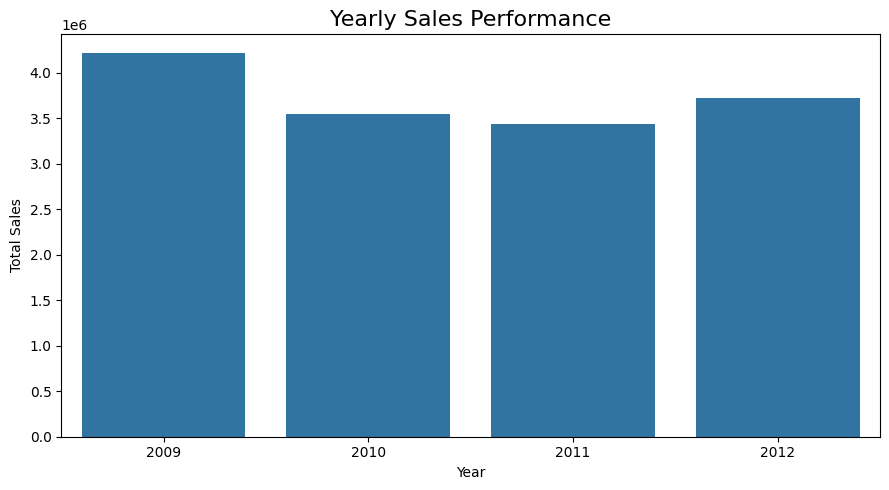

In [ ]:
# Step 10: Analyze Monthly and Yearly Sales Trends

import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate sales and profit by month
monthly_sales = (
    df_clean.groupby("Order Year-Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

# Sort months chronologically
monthly_sales = monthly_sales.sort_values("Order Year-Month")

# Display monthly sales data
print("Monthly Sales Performance:")
display(monthly_sales.head(12).round(2))

# Aggregate sales and profit by year
yearly_sales = (
    df_clean.groupby("Order Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

# Display yearly sales performance
print("\nYearly Sales Performance:")
display(yearly_sales.round(2))

# Visualize monthly sales trends
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Order Year-Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Order Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize yearly sales performance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_sales,
    x="Order Year",
    y="Total_Sales"
)

plt.title("Yearly Sales Performance", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
# Step 11: Rank Products and Customers by Sales and Profit

# Analyze product performance
product_ranking = (
    df_clean.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Order Quantity", "sum")
    )
    .reset_index()
)

# Rank products by total sales
product_ranking["Sales_Rank"] = (
    product_ranking["Total_Sales"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Display top 10 products
product_ranking = product_ranking.sort_values(
    by="Total_Sales",
    ascending=False
)

print("Top 10 Products by Sales:")
display(product_ranking.head(10).round(2))

# Display 10 least profitable products
print("\n10 Lowest-Profit Products:")
display(
    product_ranking.sort_values(
        by="Total_Profit",
        ascending=True
    ).head(10).round(2)
)

# Analyze customer performance
customer_ranking = (
    df_clean.groupby("Customer Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

# Rank customers by total sales
customer_ranking["Customer_Rank"] = (
    customer_ranking["Total_Sales"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Display top 10 customers
customer_ranking = customer_ranking.sort_values(
    by="Total_Sales",
    ascending=False
)

print("\nTop 10 Customers by Sales:")
display(customer_ranking.head(10).round(2))

# Save ranking results
product_ranking.to_csv(
    PROCESSED_DATA_DIR / "product_ranking.csv",
    index=False
)

customer_ranking.to_csv(
    PROCESSED_DATA_DIR / "customer_ranking.csv",
    index=False
)

print("\nProduct and customer ranking completed successfully!")

Top 10 Products by Sales:


,Product Name,Total_Sales,Total_Profit,Total_Quantity,Sales_Rank
565,Global Troyª Executive Leather Low-Back Tilter,275941.52,79284.78,550,1
860,Polycom ViewStationª ISDN Videoconferencing Unit,255303.97,-17771.27,41,2
323,Canon PC940 Copier,210910.68,47705.85,474,3
895,"Riverside Palais Royal Lawyers Bookcase, Royal...",206494.13,14291.57,236,4
582,Hewlett Packard LaserJet 3310 Copier,194880.35,73299.61,334,5
294,Bretford CR8500 Series Meeting Room Furniture,147412.21,-1989.87,407,6
946,Sharp AL-1530CS Digital Copier,130046.81,11770.30,260,7
591,"Hewlett-Packard cp1700 [D, PS] Series Color In...",128100.43,55281.39,269,8
515,GBC DocuBind 200 Manual Binding Machine,120342.74,50462.53,286,9
325,Canon imageCLASS 2200 Advanced Copier,114173.41,-31885.68,32,10



10 Lowest-Profit Products:


,Product Name,Total_Sales,Total_Profit,Total_Quantity,Sales_Rank
835,Okidata Pacemark 4410N Wide Format Dot Matrix ...,60619.66,-43949.37,18,49
325,Canon imageCLASS 2200 Advanced Copier,114173.41,-31885.68,32,10
557,"Global High-Back Leather Tilter, Burgundy",82752.20,-30518.90,666,31
447,Epson DFX-8500 Dot Matrix Printer,85975.08,-29400.34,35,27
632,Hoover Portapowerª Portable Vacuum,2946.43,-21088.48,465,644
860,Polycom ViewStationª ISDN Videoconferencing Unit,255303.97,-17771.27,41,2
448,Epson DFX5000+ Dot Matrix Printer,20835.42,-16160.74,14,201
689,KI Conference Tables,23289.69,-15701.27,323,172
712,Lexmark 4227 Plus Dot Matrix Printer,59735.01,-15492.81,32,52
291,BoxOffice By Design Rectangular and Half-Moon ...,104483.14,-14938.68,516,19



Top 10 Customers by Sales:


,Customer Name,Total_Sales,Total_Profit,Total_Orders,Customer_Rank
261,Emily Phan,117124.44,34005.44,8,1
218,Deborah Brumfield,97433.14,31121.22,12,2
659,Roy Skaria,92542.15,1343.94,18,3
732,Sylvia Foulston,88875.76,5141.90,18,4
309,Grant Carroll,88417.00,27977.29,17,5
17,Alejandro Grove,83561.93,20588.92,9,6
198,Darren Budd,81577.34,1857.66,26,7
405,Julia Barnett,80044.45,-1956.09,12,8
392,John Lucas,79696.19,12725.08,14,9
472,Liz MacKendrick,76306.43,20397.24,14,10



Product and customer ranking completed successfully!


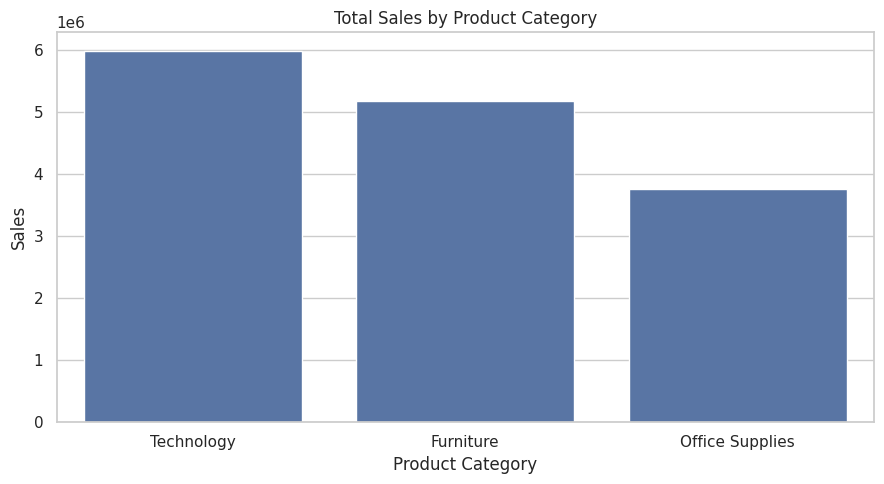

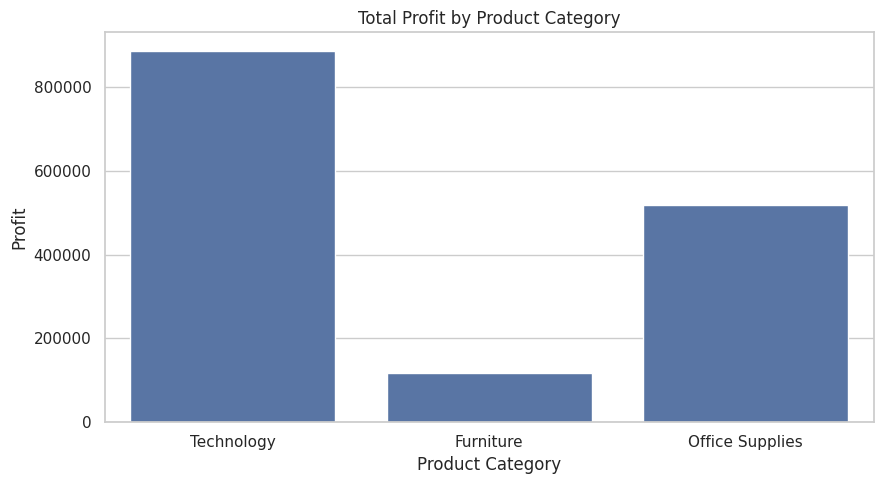

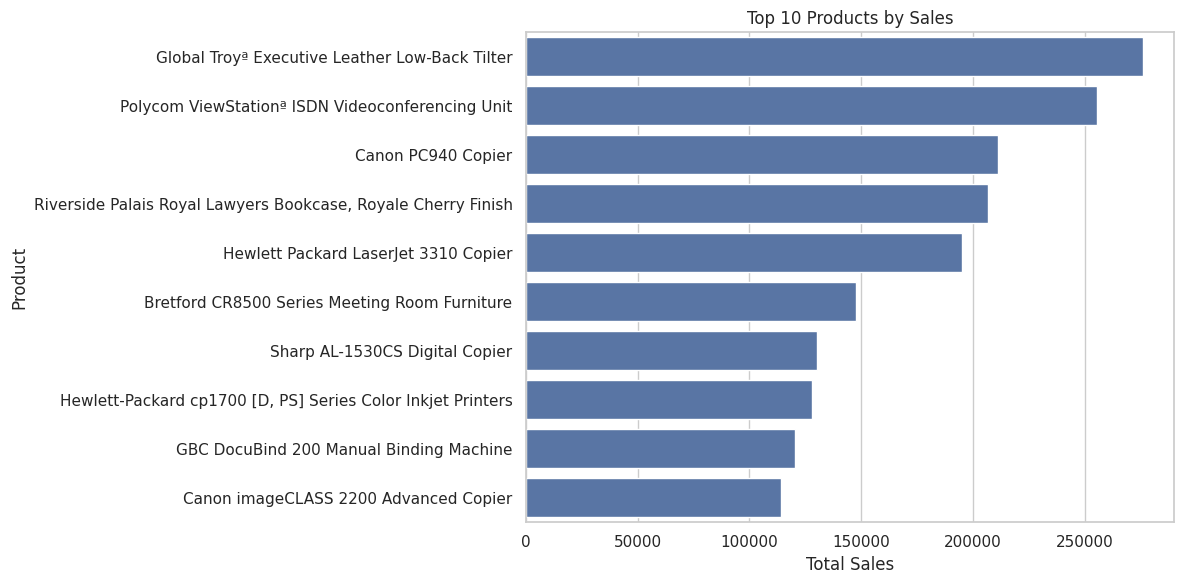

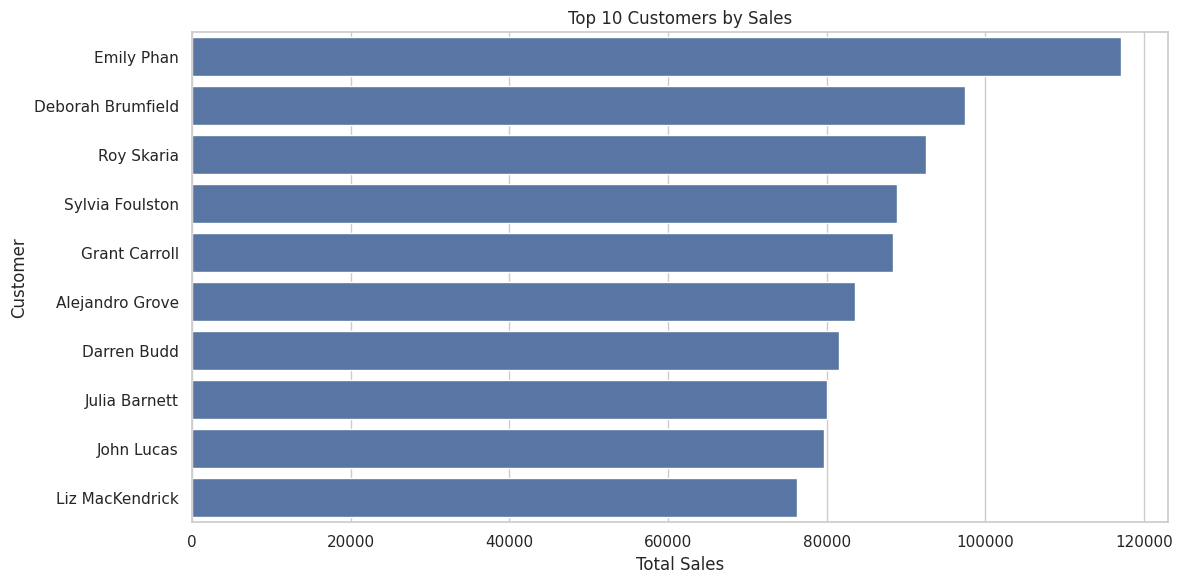

All charts created and saved successfully!
Chart location: /content/Sales_Customer_Analytics/reports/charts


In [ ]:
# Step 12: Create Visualisations for Sales and Business Performance

import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid")

# Create a folder to store charts
CHART_DIR = PROJECT_DIR / "reports" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

# Chart 1: Sales by Product Category
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Product Category",
    y="Total_Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig(CHART_DIR / "sales_by_category.png", dpi=300)
plt.show()

# Chart 2: Profit by Product Category
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis,
    x="Product Category",
    y="Total_Profit"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.savefig(CHART_DIR / "profit_by_category.png", dpi=300)
plt.show()

# Chart 3: Top 10 Products by Sales
top_products = product_ranking.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(CHART_DIR / "top_10_products.png", dpi=300)
plt.show()

# Chart 4: Top 10 Customers by Sales
top_customers = customer_ranking.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="Total_Sales",
    y="Customer Name"
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.savefig(CHART_DIR / "top_10_customers.png", dpi=300)
plt.show()

print("All charts created and saved successfully!")
print("Chart location:", CHART_DIR)

In [ ]:
# Step 13: Load the Cleaned Dataset into an SQLite Database

import sqlite3

# Create the database folder
DATABASE_DIR = PROJECT_DIR / "data" / "processed"
DATABASE_DIR.mkdir(parents=True, exist_ok=True)

# Create an SQLite database connection
DB_PATH = DATABASE_DIR / "sales_analytics.db"
conn = sqlite3.connect(DB_PATH)

# Load cleaned data into the database
df_clean.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

# Verify the number of records stored
record_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM sales",
    conn
)

print("SQLite database created successfully!")
print("Records stored:")
display(record_count)

print("Database location:", DB_PATH)

SQLite database created successfully!
Records stored:


,total_records
0,8399


Database location: /content/Sales_Customer_Analytics/data/processed/sales_analytics.db


In [ ]:
# Step 13.1: Calculate Overall Business KPIs Using SQL

query = """
SELECT
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders,
    COUNT(DISTINCT "Customer Name") AS Unique_Customers,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM sales;
"""

# Execute the SQL query
sql_kpi = pd.read_sql_query(query, conn)

# Display the results
print("Overall Business Performance Using SQL:")
display(sql_kpi)

Overall Business Performance Using SQL:


,Total_Sales,Total_Profit,Total_Orders,Unique_Customers,Profit_Margin
0,14915600.82,1521767.98,5496,795,10.2


In [ ]:
# Step 13.2: Analyze Product Category Performance Using SQL

query = """
SELECT
    "Product Category",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    SUM("Order Quantity") AS Total_Quantity,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM sales
GROUP BY "Product Category"
ORDER BY Total_Sales DESC;
"""

# Execute the SQL query
sql_category = pd.read_sql_query(query, conn)

# Display category performance
print("Product Category Performance Using SQL:")
display(sql_category)

Product Category Performance Using SQL:


,Product Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Technology,5984248.18,886313.52,52175,14.81
1,Furniture,5178590.54,117433.03,44324,2.27
2,Office Supplies,3752762.10,518021.43,118278,13.80


In [ ]:
# Step 13.3: Analyze Regional Sales Performance Using SQL

query = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM sales
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

# Execute the SQL query
sql_region = pd.read_sql_query(query, conn)

# Display regional performance
print("Regional Sales Performance Using SQL:")
display(sql_region)

Regional Sales Performance Using SQL:


,Region,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
0,West,3597549.28,297008.61,1330,8.26
1,Ontario,3063212.48,346868.54,1235,11.32
2,Prarie,2837304.60,321160.12,1148,11.32
3,Atlantic,2014248.20,238960.66,748,11.86
4,Quebec,1510195.08,140426.65,587,9.30
5,Yukon,975867.37,73849.21,396,7.57
6,Northwest Territories,800847.33,100653.08,269,12.57
7,Nunavut,116376.48,2841.11,56,2.44


In [ ]:
# Step 13.4: Analyze Customer Performance Using SQL

query = """
SELECT
    "Customer Name",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders
FROM sales
GROUP BY "Customer Name"
ORDER BY Total_Sales DESC
LIMIT 10;
"""

# Execute the SQL query
sql_customers = pd.read_sql_query(query, conn)

# Display the top 10 customers
print("Top 10 Customers by Sales Using SQL:")
display(sql_customers)

Top 10 Customers by Sales Using SQL:


,Customer Name,Total_Sales,Total_Profit,Total_Orders
0,Emily Phan,117124.44,34005.44,8
1,Deborah Brumfield,97433.14,31121.22,12
2,Roy Skaria,92542.15,1343.94,18
3,Sylvia Foulston,88875.76,5141.90,18
4,Grant Carroll,88417.00,27977.29,17
5,Alejandro Grove,83561.93,20588.92,9
6,Darren Budd,81577.34,1857.66,26
7,Julia Barnett,80044.45,-1956.09,12
8,John Lucas,79696.19,12725.08,14
9,Liz MacKendrick,76306.43,20397.24,14


In [ ]:
# Step 13.5: Analyze Monthly Sales Trends Using SQL

query = """
SELECT
    "Order Year-Month",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM sales
GROUP BY "Order Year-Month"
ORDER BY "Order Year-Month";
"""

# Execute the SQL query
sql_monthly = pd.read_sql_query(query, conn)

# Display monthly sales performance
print("Monthly Sales Trends Using SQL:")
display(sql_monthly)

# Save SQL analysis results
sql_monthly.to_csv(
    PROCESSED_DATA_DIR / "monthly_sales_sql.csv",
    index=False
)

print("Monthly SQL analysis saved successfully!")

Monthly Sales Trends Using SQL:


,Order Year-Month,Total_Sales,Total_Profit
0,2009-01,516302.96,62326.40
1,2009-02,332480.64,30422.68
2,2009-03,411628.73,22802.96
3,2009-04,393276.48,39132.73
4,2009-05,230145.54,18035.35
5,2009-06,263456.07,34640.55
6,2009-07,380503.97,41749.43
7,2009-08,329754.72,14682.84
8,2009-09,325292.31,46652.05
9,2009-10,361555.27,55228.01


Monthly SQL analysis saved successfully!


In [ ]:
# Step 14.1: Download the Cleaned Dataset for Power BI

from google.colab import files

# Download the cleaned dataset
powerbi_file = PROCESSED_DATA_DIR / "cleaned_sales_data.csv"

files.download(str(powerbi_file))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>